In [1]:
import gc, json, math, random, shutil, sys, traceback
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from tqdm.auto import tqdm

sys.path.insert(0, "kev")
from models.kev_pointer import KevPointerModel

BASE_MODEL = "jaredpalmer/kev-0.8b"
LORA_RANK = 64
device = "cuda"


In [2]:
import importlib
import data.persona as _persona_mod
import data.base as _base_mod
import data.issp as _issp_mod
import data.twin2k as _twin2k_mod
import data.grummon2025 as _grummon2025_mod
for _mod in (_persona_mod, _base_mod, _issp_mod, _twin2k_mod, _grummon2025_mod):
    importlib.reload(_mod)

from data.base import (
    PAIR_PERSONA_ATTRS,
    SINGLE_PERSONA_ATTRS,
    build_persona_dataset,
    evaluate_model,
    load_split_qids,
    make_view,
)
from data.issp import load_issp_df, load_issp_eval
from data.twin2k import load_twin2k_df
from data.grummon2025 import load_grummon2025

# 1. Load question-ID splits in the notebook ({"train": ["2015:v1", ...], "valid": [...], "test": [...]})
issp_qids = load_split_qids("splits/split.json")

# 2. Pass training question IDs to dataset loaders
issp_train_df = load_issp_df(qids=issp_qids["train"])
twin_df = load_twin2k_df()  # qids=None loads all Twin-2K-500 questions
train_df = pd.concat([issp_train_df, twin_df], ignore_index=True)

print(
    f"train : {len(train_df):>9,} answers across {train_df['qid'].nunique():>4} questions "
    f"(ISSP={len(issp_qids['train'])}, Twin2K={twin_df['qid'].nunique()})\n"
    f"valid : {len(issp_qids['valid']):>4} ISSP questions\n"
    f"test  : {len(issp_qids['test']):>4} ISSP questions"
)


train : 1,737,940 answers across 1468 questions (ISSP=494, Twin2K=974)
valid :   50 ISSP questions
test  :   72 ISSP questions


## Build persona datasets

In [3]:
MIN_N = 100
INCLUDE_COUNTRY = False
TEST10_SEED = 42

# 1. Build (or load from .cache/) ISSP + Twin-2K-500 training sets
# train_records_k1 = build_persona_dataset(
#     train_df, attr_sets=SINGLE_PERSONA_ATTRS, include_country=INCLUDE_COUNTRY, min_n=MIN_N, desc="train_records_k1"
# )
# train_records_k2 = build_persona_dataset(
#     train_df, attr_sets=PAIR_PERSONA_ATTRS, include_country=INCLUDE_COUNTRY, min_n=MIN_N, desc="train_records_k2"
# )
train_records_issp_twin2k_resp = build_persona_dataset(
    train_df, attr_sets=None, include_country=INCLUDE_COUNTRY, desc="train_records_resp"
)

# 2. Build validation and test evaluation sets (respondent-level: attr_sets=None)
issp_test10_qids = random.Random(TEST10_SEED).sample(sorted(issp_qids["test"]), 10)

issp_resp_valid_grouped = load_issp_eval(
    qids=issp_qids["valid"], attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, name="valid", valid=False
)
issp_resp_test_grouped = load_issp_eval(
    qids=issp_qids["test"], attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, name="test", valid=False
)
issp_resp_test10_grouped = load_issp_eval(
    qids=issp_test10_qids, attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, name="test_10", valid=True
)
grummon2025_grouped = load_grummon2025(
    attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, valid=False
)

valid_records = issp_resp_valid_grouped["records"]
test_records = issp_resp_test_grouped["records"]
test10_records = issp_resp_test10_grouped["records"]
grummon2025_records = grummon2025_grouped["records"]

print(
    # f"Training records : k1={len(train_records_k1):,}, k2={len(train_records_k2):,}, resp={len(train_records_resp):,}\n"
    f"Eval sets        : valid={len(valid_records):,} ({len(issp_resp_valid_grouped['packed_views']):,} states), "
    f"test={len(test_records):,} ({len(issp_resp_test_grouped['packed_views']):,} states), "
    f"test_10={len(test10_records):,} ({len(issp_resp_test10_grouped['packed_views']):,} states), "
    f"grummon2025={len(grummon2025_records):,} ({len(grummon2025_grouped['packed_views']):,} states)"
)
# pd.DataFrame(train_records_k1)[["qid", "type", "attribute", "persona", "n", "human_dist"]].head(5)

Loaded 1,737,940 records from train_records_resp_minNone_d98864c0.pkl
Loaded 64,201 records from valid_records_minNone_eaa9b07e.pkl
Loaded 92,992 records from test_records_minNone_6a10f9dc.pkl
Loaded 13,006 records from test_10_records_minNone_4228e0b9.pkl
Eval sets        : valid=64,201 (14,236 states), test=92,992 (14,263 states), test_10=13,006 (8,026 states), grummon=33,798 (3,652 states)


In [16]:
len(test10_records)

13006

In [14]:
# train_records_resp[0]
# valid_records[0]
(issp_resp_valid_grouped).keys()
issp_resp_test_grouped['packed_views'][-1]

{'state': 'Sex: Female\nAge: 65+\nEducation: Less than high school\nReligion: Protestant\nAttendance of religious services: Never\nVoted in the last general election: No\nPlace of living: A farm or home in the country\nMarital status: Widowed\nMain activity: Retired\nTrade union membership: No\nRegion: Midwest',
 'questions': {'2024:v44': {'type': 'score',
   'instructions': 'Here are some statements about technology. Technology includes all kinds of machinery, equipment, digital devices, and software. How much do you agree or disagree with this statement? Technology provides more opportunities for the next generation.',
   'criteria': ['Strongly agree',
    'Agree',
    'Neither agree nor disagree',
    'Disagree',
    'Strongly disagree'],
   'target': {'0': 0.0, '1': 1.0, '2': 0.0, '3': 0.0, '4': 0.0}},
  '2024:v58': {'type': 'choice',
   'instructions': 'Here are some different forms of political and social action that people can take. Have you done the following in the last 12 mon

In [48]:
rng = random.Random()
sample_input, sample_meta = make_view(train_records_issp_twin2k_resp[0], rng), train_records_issp_twin2k_resp[0]
sample_input
# sample_meta

{'state': 'Main activity: Retired\nSex: Male\nEducation: College graduate/some postgrad\nPolitical ideology: Conservative\nIncome: $75,000 - $89,999\nVoted in the last general election: Yes\nPlace of living: The suburbs or outskirts of a big city\nRegion: Northeast\nMarital status: Married\nReligion: Catholic\nAge: 65+\nPolitical party: Republican\nAttendance of religious services: Once a week\nTrade union membership: No\nAncestry: Italy',
 'questions': {'2015:v1': {'type': 'score',
   'instructions': 'Please tick one box for each statement below to show how much you agree or disagree with it, thinking of work in general. A job is just a way of earning money - no more.',
   'criteria': ['Strongly agree',
    'Agree',
    'Neither agree nor disagree',
    'Disagree',
    'Strongly disagree'],
   'target': {'0': 0.0, '1': 1.0, '2': 0.0, '3': 0.0, '4': 0.0}}}}

## Functions

In [4]:
import importlib
import data.base as _base_mod
import models.kev_pointer as _kev_pointer_mod
importlib.reload(_base_mod)
importlib.reload(_kev_pointer_mod)
from data.base import evaluate_model, make_view
from models.kev_pointer import Checkpoint, KevPointerModel, LoadOptions


def free_gpu():
    if hasattr(sys, "last_traceback") and sys.last_traceback is not None:
        traceback.clear_frames(sys.last_traceback)
        sys.last_traceback = None
    for attr in ("last_value", "last_type", "last_exc"):
        if hasattr(sys, attr):
            setattr(sys, attr, None)
    gc.collect()
    torch.cuda.empty_cache()


def save_checkpoint(model, save_dir, name, extra):
    """Atomically write checkpoint to save_dir / name via a temporary directory."""
    save_dir = Path(save_dir)
    folder, tmp = save_dir / name, save_dir / f"{name}-tmp"
    shutil.rmtree(tmp, ignore_errors=True)
    model.save(tmp, extra=extra)
    (tmp / "metrics.json").write_text(json.dumps(extra, indent=2) + "\n")
    shutil.rmtree(folder, ignore_errors=True)
    tmp.rename(folder)


def load_checkpoint(ckpt_dir, device="cuda", trainable=False):
    ckpt_dir = Path(ckpt_dir)
    if not (ckpt_dir / "head.pt").exists():
        raise FileNotFoundError(f"Checkpoint not found: {ckpt_dir / 'head.pt'}")
    free_gpu()
    if trainable:
        m = KevPointerModel.build(str(ckpt_dir), device=device)
        m.net.head.temperature = 1.0
        return m
    ck = Checkpoint(str(ckpt_dir))
    tok, net = ck.load(device, LoadOptions(dtype=torch.bfloat16, temperature=1.0, cuda_graphs=True, fused=True))
    m = KevPointerModel(net, tok, ck.meta, "loaded")
    m.net.head.temperature = 1.0
    return m


def _normalize_eval_sets(eval_records):
    """Normalize `eval_records` into a list of grouped bundle dicts and verify exactly one has `valid=True`."""
    if isinstance(eval_records, dict) and "records" in eval_records:
        eval_records["valid"] = True
        eval_sets = [eval_records]
    elif isinstance(eval_records, (list, tuple)):
        eval_sets = list(eval_records)
    else:
        raise ValueError("eval_records must be a grouped evaluation dict or a list of grouped evaluation dicts")

    if not eval_sets:
        raise ValueError("eval_records must not be empty")
    for s in eval_sets:
        if not isinstance(s, dict) or not s.get("name"):
            raise ValueError("Each evaluation set must be a grouped dict with a non-empty 'name'")
        if "valid" not in s:
            raise KeyError(f"Evaluation set {s['name']!r} is missing required 'valid' boolean flag")

    valid_sets = [s for s in eval_sets if s["valid"]]
    if len(valid_sets) != 1:
        raise ValueError(
            f"Exactly one evaluation set in eval_records must have valid=True, got {len(valid_sets)}: "
            f"{[(s['name'], s['valid']) for s in eval_sets]}"
        )
    return eval_sets, valid_sets[0]["name"]


class TrainingPlotter:
    PALETTE = ["tab:orange", "tab:green", "tab:purple", "tab:red", "tab:brown"]

    def __init__(self, total_steps, log_every, eval_sets, val_name):
        self.total_steps = total_steps
        self.log_every = log_every
        self.val_name = val_name
        self.eval_specs = [
            {
                "name": s["name"],
                "valid": bool(s["valid"]),
                "n_records": len(s["records"]),
                "n_states": len(s["packed_views"]),
                "has_ols": s.get("eval_fn") is not None,
            }
            for s in eval_sets
        ]
        self.ols_names = [sp["name"] for sp in self.eval_specs if sp["has_ols"]]
        self.window_kls = []
        self.val_rows = []
        self.latest_ols_df = {}
        self.latest_ols_summary = {}
        self.history = {
            "step": [],
            "step_kl": [],
            "logged_step": [],
            "window_kl": [],
            "val_step": [],
            "eval_kls": {sp["name"]: [] for sp in self.eval_specs},
        }

        n_plots = 1 + len(self.eval_specs) + len(self.ols_names)
        self.fig, axes = plt.subplots(n_plots, 1, figsize=(10, 3.4 * n_plots))
        if n_plots == 1:
            axes = [axes]
        self.ax_train = axes[0]
        self.ax_evals = {
            sp["name"]: axes[1 + i] for i, sp in enumerate(self.eval_specs)
        }
        self.ax_ols = {
            name: axes[1 + len(self.eval_specs) + j] for j, name in enumerate(self.ols_names)
        }
        self.handle = display(self.fig, display_id=True)
        plt.close(self.fig)
        self.table_handle = display(pd.DataFrame(), display_id=True)
        self.ols_table_handle = display(pd.DataFrame(), display_id=True) if self.ols_names else None

    def log_step(self, step, step_kls):
        self.window_kls.extend(step_kls)
        self.history["step"].append(step)
        self.history["step_kl"].append(sum(step_kls) / len(step_kls))
        if step % self.log_every == 0:
            mean_kl = sum(self.window_kls) / len(self.window_kls)
            self.history["logged_step"].append(step)
            self.history["window_kl"].append(mean_kl)
            self.window_kls = []
            self.redraw(step)
            return mean_kl
        return None

    def log_eval(self, step, eval_summaries, eval_extra_dfs, epoch=0):
        self.history["val_step"].append(step)
        train_kl = self.history["window_kl"][-1] if self.history["window_kl"] else np.nan
        row = {
            "epoch": epoch,
            "step": step,
            "train_kl": train_kl,
        }
        for sp in self.eval_specs:
            name = sp["name"]
            s = eval_summaries[name]
            kl = float(s["dist_kl"])
            self.history["eval_kls"][name].append(kl)
            row[f"{name}_kl"] = kl
            if sp["has_ols"]:
                for k in ("OLS MAPE (%)", "OLS MAE", "OLS MSE", "Spearman rho"):
                    if k in s:
                        row[f"{name}_{k}"] = float(s[k])
                self.latest_ols_summary[name] = s
                if name in eval_extra_dfs and eval_extra_dfs[name] is not None:
                    self.latest_ols_df[name] = eval_extra_dfs[name]

        self.val_rows.append(row)
        self.redraw(step)
        self.redraw_table()

    def redraw_table(self):
        df = pd.DataFrame(self.val_rows)
        val_col = f"{self.val_name}_kl"
        best_idx = df[val_col].idxmin()
        fmt = {c: "{:.4f}" for c in df.columns if c not in ("epoch", "step")}
        for c in df.columns:
            if "MAPE" in c:
                fmt[c] = "{:.2f}"
        styled = (
            df.style
            .apply(
                lambda r: [
                    "background-color: #d4edda; color: #155724; font-weight: bold"
                    if r.name == best_idx else ""
                    for _ in r
                ],
                axis=1,
            )
            .format(fmt, na_rep="—")
        )
        self.table_handle.update(styled)

        if self.ols_table_handle is not None and self.latest_ols_df:
            name = self.ols_names[0]
            if name in self.latest_ols_df:
                ols_df = self.latest_ols_df[name].copy()
                self.ols_table_handle.update(ols_df.style.format("{:.4f}"))

    def redraw(self, step):
        self.ax_train.clear()
        if self.history["logged_step"]:
            self.ax_train.plot(
                self.history["logged_step"],
                self.history["window_kl"],
                color="tab:blue",
                linewidth=2,
                label=f"train KL (mean over {self.log_every} steps)",
            )
            self.ax_train.set_yscale("log")
            self.ax_train.legend(loc="upper right")
        self.ax_train.set_ylabel("Train KL (bits)")
        self.ax_train.set_title(f"Training KL — step {step}/{self.total_steps}")
        self.ax_train.set_xlabel("Step")

        for i, sp in enumerate(self.eval_specs):
            name = sp["name"]
            ax = self.ax_evals[name]
            ax.clear()
            kls = self.history["eval_kls"][name]
            color = self.PALETTE[i % len(self.PALETTE)]
            if kls:
                best_kl = min(kls)
                ax.plot(
                    self.history["val_step"],
                    kls,
                    color=color,
                    marker="o",
                    linewidth=2,
                    label=f"{name} KL (best={best_kl:.4f} bits, last={kls[-1]:.4f})",
                )
                ax.set_yscale("log")
                ax.legend(loc="upper right")
            tag = " [VALID — saves best]" if sp["valid"] else ""
            ax.set_ylabel(f"{name} KL (bits)")
            ax.set_xlabel("Step")
            ax.set_title(f"{name}{tag} ({sp['n_records']:,} records, {sp['n_states']:,} states)")

        for name in self.ols_names:
            ax = self.ax_ols[name]
            ax.clear()
            if name in self.latest_ols_df:
                bdf = self.latest_ols_df[name]
                arms = list(bdf.index)
                x = np.arange(len(arms))
                width = 0.36
                ax.bar(x - width / 2, bdf["human"].values, width, label="Human RCT", color="tab:gray")
                ax.bar(x + width / 2, bdf["model"].values, width, label=f"Model (step {step})", color="tab:green")
                ax.axhline(0.0, color="black", linewidth=0.8, linestyle="--")
                ax.set_xticks(x)
                ax.set_xticklabels(arms, rotation=15, ha="right")
                ax.set_ylabel("OLS Treatment Effect (vs. Positive)")
                s = self.latest_ols_summary.get(name, {})
                mape = s.get("OLS MAPE (%)", float("nan"))
                mae = s.get("OLS MAE", float("nan"))
                rho = s.get("Spearman rho", float("nan"))
                ax.set_title(
                    f"{name} Current Model OLS Betas — MAPE={mape:.2f}%, MAE={mae:.4f}, Spearman rho={rho:.3f}"
                )
                ax.legend(loc="upper right")

        self.fig.tight_layout()
        self.handle.update(self.fig)


def train_stage(
    model,
    train_records,
    eval_records,
    save_dir,
    *,
    init_from,
    epochs,
    lr=1e-4,
    pct_start=0.1,
    batch_size=8,
    grad_accum_steps=1,
    eval_batch_size=128,
    log_every=20,
    val_every=200,
    samples_per_epoch=None,
    seed=0,
    resume=False,
):
    if model is None:
        raise ValueError("model must be loaded before calling train_stage")

    if model.net.graphs is not None:
        model.net.graphs = None
    free_gpu()

    eval_sets, val_name = _normalize_eval_sets(eval_records)
    save_dir = Path(save_dir)
    rng = random.Random(seed)
    effective_bs = batch_size * grad_accum_steps
    n_per_epoch = min(samples_per_epoch, len(train_records)) if samples_per_epoch else len(train_records)
    steps_per_epoch = math.ceil(n_per_epoch / effective_bs)
    total_steps = epochs * steps_per_epoch

    state_path = save_dir / "last" / "trainer_state.pt"
    if resume and not state_path.exists():
        raise FileNotFoundError(f"Cannot resume: {state_path} does not exist")

    optimizer = torch.optim.AdamW(model.trainable_parameters(), lr=lr, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, total_steps=total_steps, pct_start=pct_start)
    plotter = TrainingPlotter(total_steps, log_every, eval_sets, val_name)
    overall = None

    def run_all_evals():
        summaries = {}
        extra_dfs = {}
        for s in eval_sets:
            name = s["name"]
            if overall is not None:
                overall.set_postfix_str(f"eval: {name}...")
            summary, _ = evaluate_model(model, s, batch_size=eval_batch_size, show_progress=True)
            summaries[name] = summary
            extra_dfs[name] = s.get("last_extra_df")
        return summaries, extra_dfs

    if resume:
        st = torch.load(state_path, map_location="cpu", weights_only=False)
        step = st["step"]
        start_epoch = st["epoch"]
        resume_start_idx = st["next_start"]
        best_val_kl = st["best_val_kl"]
        rng.setstate(st["rng_state"])
        epoch_records_saved = st["epoch_records"]
        optimizer.load_state_dict(st["optimizer"])
        scheduler.load_state_dict(st["scheduler"])
        plotter.history = st["history"]
        plotter.val_rows = st["val_rows"]
        plotter.latest_ols_df = st.get("latest_ols_df", {})
        plotter.latest_ols_summary = st.get("latest_ols_summary", {})
        plotter.redraw(step)
        plotter.redraw_table()
        overall = tqdm(total=total_steps, initial=step, desc=save_dir.name, unit="step")
        print(f"Resumed {save_dir.name} at epoch {start_epoch + 1}, step {step}/{total_steps} (best_{val_name}_kl={best_val_kl:.4f})")
    else:
        step = 0
        start_epoch = 0
        resume_start_idx = 0
        epoch_records_saved = None
        overall = tqdm(total=total_steps, initial=step, desc=save_dir.name, unit="step")
        summaries_0, extra_dfs_0 = run_all_evals()
        best_val_kl = float(summaries_0[val_name]["dist_kl"])
        plotter.log_eval(0, summaries_0, extra_dfs_0, epoch=0)

    def validate_and_save(epoch_idx, next_start, epoch_records):
        nonlocal best_val_kl
        summaries, extra_dfs = run_all_evals()
        val_summary = summaries[val_name]
        val_ce = float(val_summary["ce"])
        val_kl = float(val_summary["dist_kl"])
        plotter.log_eval(step, summaries, extra_dfs, epoch=epoch_idx + 1)

        train_kl = float(plotter.history["window_kl"][-1])
        extra = {
            "init_from": str(init_from),
            "step": step,
            "epoch": epoch_idx + 1,
            "val_set": val_name,
            "train_kl": train_kl,
            "val_ce": val_ce,
            "val_dist_kl": val_kl,
            "eval_metrics": {name: {k: float(v) for k, v in s.items()} for name, s in summaries.items()},
            "settings": {
                "lr": lr, "pct_start": pct_start, "batch_size": batch_size,
                "grad_accum_steps": grad_accum_steps, "effective_batch_size": effective_bs,
                "epochs": epochs, "samples_per_epoch": samples_per_epoch, "seed": seed,
            },
        }
        if val_kl < best_val_kl:
            best_val_kl = val_kl
            save_checkpoint(model, save_dir, "best", extra=extra)
        save_checkpoint(model, save_dir, "last", extra=extra)

        at_epoch_end = next_start >= len(epoch_records)
        torch.save({
            "step": step,
            "epoch": epoch_idx + 1 if at_epoch_end else epoch_idx,
            "next_start": 0 if at_epoch_end else next_start,
            "best_val_kl": best_val_kl,
            "rng_state": rng.getstate(),
            "epoch_records": None if at_epoch_end else epoch_records,
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "history": plotter.history,
            "val_rows": plotter.val_rows,
            "latest_ols_df": plotter.latest_ols_df,
            "latest_ols_summary": plotter.latest_ols_summary,
        }, state_path)

    model.train()

    try:
        for e in range(start_epoch, epochs):
            if e == start_epoch and epoch_records_saved is not None:
                epoch_records = epoch_records_saved
                first_start = resume_start_idx
            else:
                epoch_records = rng.sample(train_records, n_per_epoch)
                first_start = 0

            for start in range(first_start, len(epoch_records), effective_bs):
                macro_batch = epoch_records[start:start + effective_bs]
                step_kls = []
                for sub_start in range(0, len(macro_batch), batch_size):
                    batch = macro_batch[sub_start:sub_start + batch_size]
                    prepared = [model.prepare(make_view(r, rng=rng)) for r in batch]
                    logits_batch = model.forward([enc for enc, _ in prepared])

                    losses = []
                    for (_, targets), record_logits in zip(prepared, logits_batch):
                        for z, q in zip(record_logits, targets):
                            t = q["target"].to(device)
                            logp = torch.log_softmax(z.float(), dim=-1)
                            losses.append(-(t * logp).sum())
                            nz = t > 0
                            step_kls.append(((t[nz] * (t[nz].log() - logp[nz])).sum() / math.log(2)).item())

                    loss = torch.stack(losses).sum() / len(macro_batch)
                    loss.backward()

                grad_norm = torch.nn.utils.clip_grad_norm_(model.trainable_parameters(), 1.0)
                if torch.isfinite(grad_norm):
                    optimizer.step()
                else:
                    print(f"Skipping optimizer.step() at step {step + 1}: non-finite grad_norm={grad_norm.item()}")
                scheduler.step()
                optimizer.zero_grad(set_to_none=True)
                logits_batch = record_logits = losses = loss = z = t = logp = nz = grad_norm = None

                step += 1
                overall.update(1)
                mean_kl = plotter.log_step(step, step_kls)
                if mean_kl is not None:
                    overall.set_postfix(train_kl=f"{mean_kl:.3f}", lr=f"{scheduler.get_last_lr()[0]:.1e}")

                if step % val_every == 0:
                    validate_and_save(e, start + effective_bs, epoch_records)

        if step % val_every != 0:
            validate_and_save(epochs - 1, len(epoch_records), epoch_records)

    finally:
        overall.close()
        optimizer.zero_grad(set_to_none=True)
        del optimizer, scheduler
        validate_and_save = model = None
        logits_batch = record_logits = losses = loss = z = t = logp = nz = grad_norm = None
        _, _, tb = sys.exc_info()
        if tb is not None:
            traceback.clear_frames(tb)
        del tb
        free_gpu()

    return plotter

## Initialize Kev-0.8B (`lora_rank=64`) and evaluate baseline

In [ ]:
BASE_MODEL = "jaredpalmer/kev-0.8b"
LORA_RANK = 64
device = "cuda"

model = KevPointerModel.build(BASE_MODEL, device, lora_rank=LORA_RANK)
model.net.head.temperature = 1.0
print(model.describe())

header, preview_text = model.encoder.preview(make_view(train_records_resp[0]))
print(header)
print(preview_text)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

{'kind': 'kev', 'base': 'Qwen/Qwen3.5-0.8B-Base', 'mode': 'lora_rank 64', 'trainable_params': 43815424}
73 tokens; state 9 of at most 384
<|fim_prefix|>
Country: United States
Sex: Male
<|fim_middle|>
Please tick one box for each statement below to show how much you agree or disagree with it, thinking of work in general. A job is just a way of earning money - no more.
<|box_start|>Strongly agree<|box_end|>
<|box_start|>Agree<|box_end|>
<|box_start|>Neither agree nor disagree<|box_end|>
<|box_start|>Disagree<|box_end|>
<|box_start|>Strongly disagree<|box_end|>
<|fim_suffix|>


In [ ]:
val_summary_init, _ = evaluate_model(model, issp_valid_grouped, batch_size=64)
test_summary_init, _ = evaluate_model(model, issp_test_grouped, batch_size=64)
grummon2025_summary_init, _ = evaluate_model(model, grummon2025_grouped, batch_size=128)
print("Initial validation metrics:\n", val_summary_init)
print("\nInitial test metrics (ISSP):\n", test_summary_init)
print("\nInitial Grummon 2025 RCT metrics:\n", grummon2025_summary_init)


predict:   0%|          | 0/34 [00:00<?, ?batch/s]

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


predict:   0%|          | 0/49 [00:00<?, ?batch/s]

Initial validation metrics:
 ce           2.794479
dist_kl      0.950042
w1           0.154725
delta_cns    0.105351
dtype: float64

Initial test metrics:
 ce           2.872090
dist_kl      1.043820
w1           0.170714
delta_cns    0.096258
dtype: float64


## 1 attribute training

In [ ]:
resume = False
eval_records = issp_test_grouped  # or `[issp_test_grouped, grummon2025_grouped]`
stage1_dir = Path("runs/kev-0.8b-stage1-k1")

model = None
free_gpu()
if resume:
    model = load_checkpoint(stage1_dir / "last", device=device, trainable=True)
else:
    model = KevPointerModel.build(BASE_MODEL, device, lora_rank=LORA_RANK)
    model.net.head.temperature = 1.0


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

In [ ]:
plotter_s1 = train_stage(
    model,
    train_records=train_records_k1,
    eval_records=eval_records,
    save_dir=stage1_dir,
    init_from=BASE_MODEL,
    epochs=10,
    lr=1e-4,
    batch_size=8,
    val_every=200,
    resume=resume,
)

## 2 attributes training

In [19]:
resume = False
stage2_dir = Path("runs/kev-0.8b-stage2-k2")

model = None
ckpt = (stage2_dir / "last") if resume else (stage1_dir / "best")
model = load_checkpoint(ckpt, device=device, trainable=True)


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

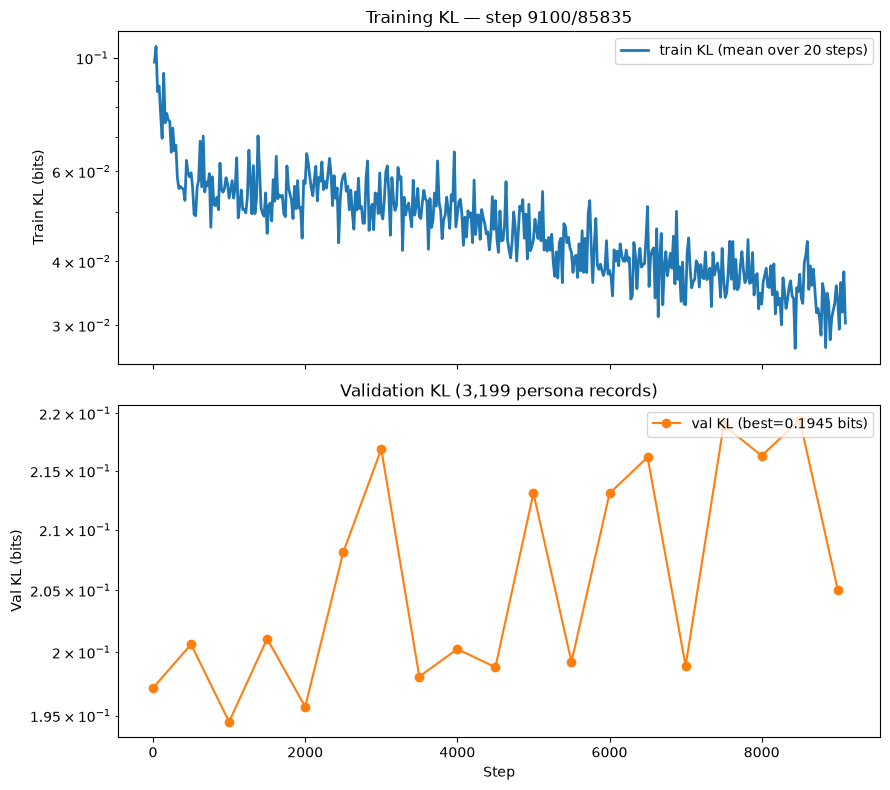

,epoch,step,train_kl,eval_kl,w1,delta_cns
0,0,0,—,0.1972,0.1088,-0.0287
1,1,500,0.0596,0.2006,0.1097,-0.0237
2,1,1000,0.0532,0.1945,0.1088,-0.0207
3,1,1500,0.0453,0.2011,0.1100,-0.0220
4,1,2000,0.0568,0.1957,0.1061,-0.0234
5,1,2500,0.0587,0.2081,0.1100,-0.0006
6,1,3000,0.0497,0.2169,0.1189,-0.0261
7,1,3500,0.0490,0.1981,0.1095,-0.0287
8,1,4000,0.0494,0.2002,0.1138,-0.0384
9,1,4500,0.0526,0.1988,0.1120,-0.0419


kev-0.8b-stage2-k2:   0%|          | 0/85835 [00:00<?, ?step/s]

KeyboardInterrupt: 

In [20]:
plotter_s2 = train_stage(
    model,
    train_records=train_records_k2,
    eval_records=eval_records,
    save_dir=stage2_dir,
    init_from=stage1_dir / "best",
    epochs=5,
    lr=5e-5,
    batch_size=8,
    val_every=500,
    resume=resume,
)

## response-level training

In [5]:
resume = False
from_scratch = True

issp_resp_test10_grouped["valid"] = True
grummon2025_grouped["valid"] = False
eval_records = [issp_resp_test10_grouped, grummon2025_grouped]

stage2_dir = Path("runs/kev-0.8b-stage2-k2")
stage3_dir = Path("runs/kev-0.8b-resp-issp+twin2k-bs64")

model = None
free_gpu()
if resume:
    ckpt = stage3_dir / "last"
    model = load_checkpoint(ckpt, device=device, trainable=True)
elif from_scratch:
    ckpt = BASE_MODEL
    model = KevPointerModel.build(BASE_MODEL, device, lora_rank=LORA_RANK)
    model.net.head.temperature = 1.0
else:
    ckpt = stage2_dir / "best"
    model = load_checkpoint(ckpt, device=device, trainable=True)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

effective_bs=64 (batch_size=4 x grad_accum_steps=16), total_steps=135,780, warmup_steps=2,000 (pct_start=0.01473)


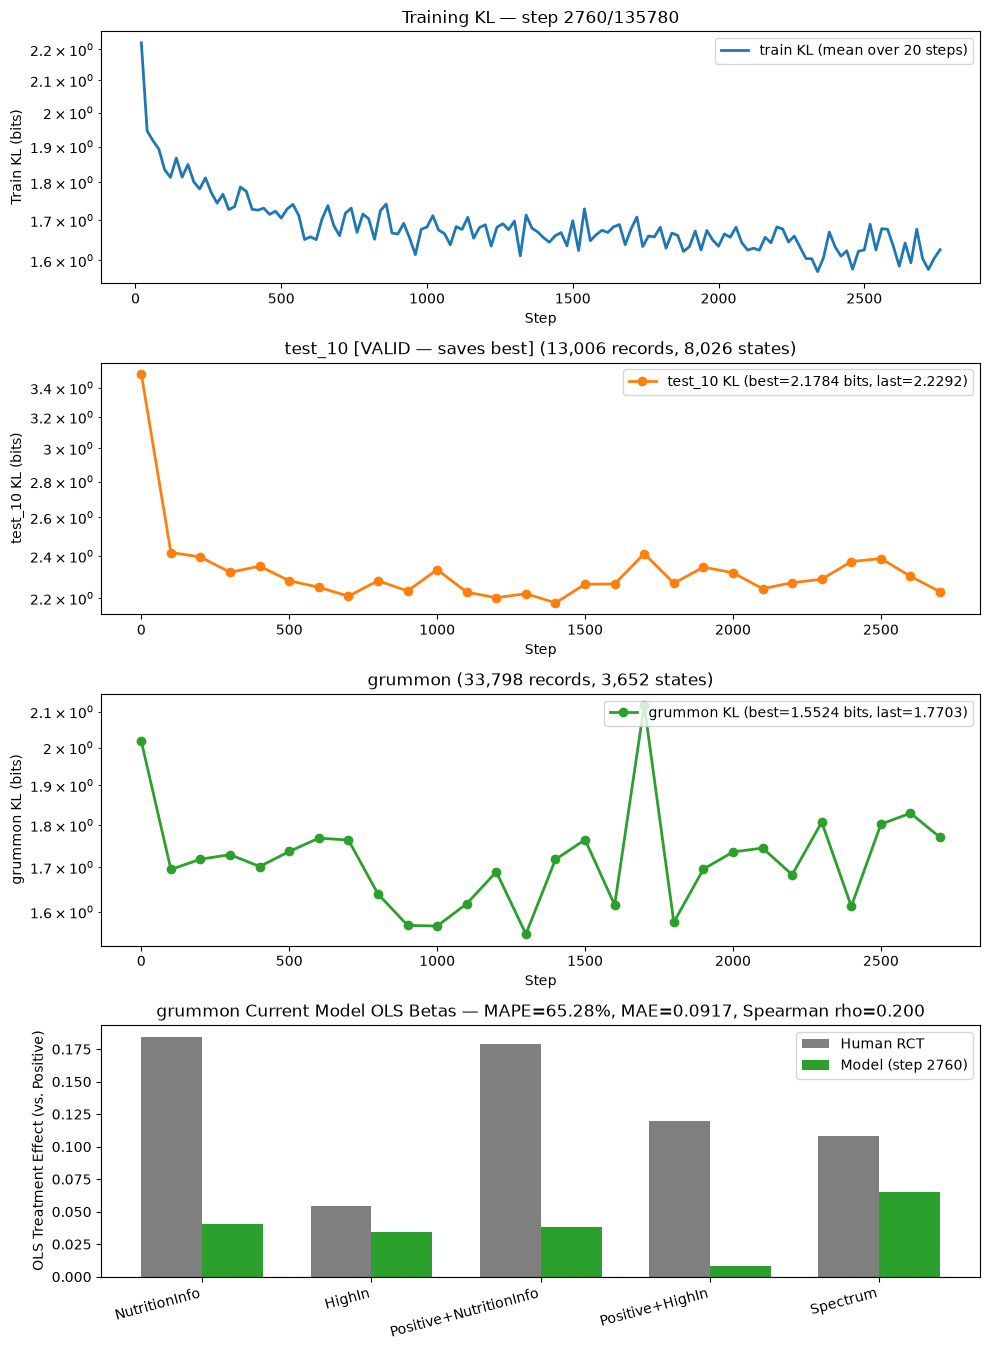

,epoch,step,train_kl,test_10_kl,grummon_kl,grummon_OLS MAPE (%),grummon_OLS MAE,grummon_OLS MSE,grummon_Spearman rho
0,0,0,—,3.4981,2.0168,104.35,0.1161,0.0148,-0.9000
1,1,100,1.8350,2.4177,1.6949,75.07,0.1082,0.0159,-0.9000
2,1,200,1.8013,2.3953,1.7185,74.05,0.1037,0.0142,-0.9000
3,1,300,1.7681,2.3207,1.7291,71.66,0.0989,0.0126,-0.7000
4,1,400,1.7284,2.3503,1.7016,70.84,0.0896,0.0095,-0.4000
5,1,500,1.7055,2.2804,1.7367,65.92,0.0910,0.0105,-0.4000
6,1,600,1.6580,2.2501,1.7685,71.51,0.0894,0.0090,-0.3000
7,1,700,1.6609,2.2088,1.7638,58.87,0.0781,0.0072,-0.1000
8,1,800,1.7037,2.2805,1.6392,50.20,0.0616,0.0045,0.6000
9,1,900,1.6652,2.2328,1.5709,48.97,0.0623,0.0047,-0.1000


,human,model,abs_diff
NutritionInfo,0.1844,0.0409,0.1435
HighIn,0.0541,0.0341,0.0200
Positive+NutritionInfo,0.1788,0.0382,0.1407
Positive+HighIn,0.1194,0.0084,0.1111
Spectrum,0.1083,0.0650,0.0434


kev-0.8b-resp-issp+twin2k-bs64:   0%|          | 0/135780 [00:00<?, ?step/s]

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


Evaluating test_10 (shared-state):   0%|          | 0/63 [00:00<?, ?batch/s]

Evaluating grummon (shared-state):   0%|          | 0/29 [00:00<?, ?batch/s]

... (51 outputs left out)

Evaluating grummon (shared-state):   0%|          | 0/29 [00:00<?, ?batch/s]

Evaluating test_10 (shared-state):   0%|          | 0/63 [00:00<?, ?batch/s]

Evaluating grummon (shared-state):   0%|          | 0/29 [00:00<?, ?batch/s]

KeyboardInterrupt: 

In [6]:
epochs = 5
lr = 5e-5
batch_size = 4
grad_accum_steps = 16
samples_per_epoch = None
warmup_steps = 2000
val_every = 100

train_set = train_records_issp_twin2k_resp

effective_bs = batch_size * grad_accum_steps
n_per_epoch = min(samples_per_epoch, len(train_set)) if samples_per_epoch else len(train_set)
total_steps = epochs * math.ceil(n_per_epoch / effective_bs)
pct_start = min(0.1, warmup_steps / total_steps)
print(
    f"effective_bs={effective_bs} (batch_size={batch_size} x grad_accum_steps={grad_accum_steps}), "
    f"total_steps={total_steps:,}, warmup_steps={int(pct_start * total_steps):,} (pct_start={pct_start:.5f})"
)

plotter_s3 = train_stage(
    model,
    train_records=train_set,
    eval_records=eval_records,
    save_dir=stage3_dir,
    init_from=ckpt,
    epochs=epochs,
    lr=lr,
    pct_start=pct_start,
    batch_size=batch_size,
    grad_accum_steps=grad_accum_steps,
    val_every=val_every,
    samples_per_epoch=samples_per_epoch,
    resume=resume,
)

## Mix data training

In [37]:
resume = False
stage4_dir = Path("runs/kev-0.8b-stage4-mix")

model = None
ckpt = (stage4_dir / "last") if resume else (stage2_dir / "best")
model = load_checkpoint(ckpt, device=device, trainable=True)

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

In [38]:
train_combined = train_records_resp + train_records_k1 + train_records_k2
# train_combined[0]
# len(train_combined)
# train_combined[-1]


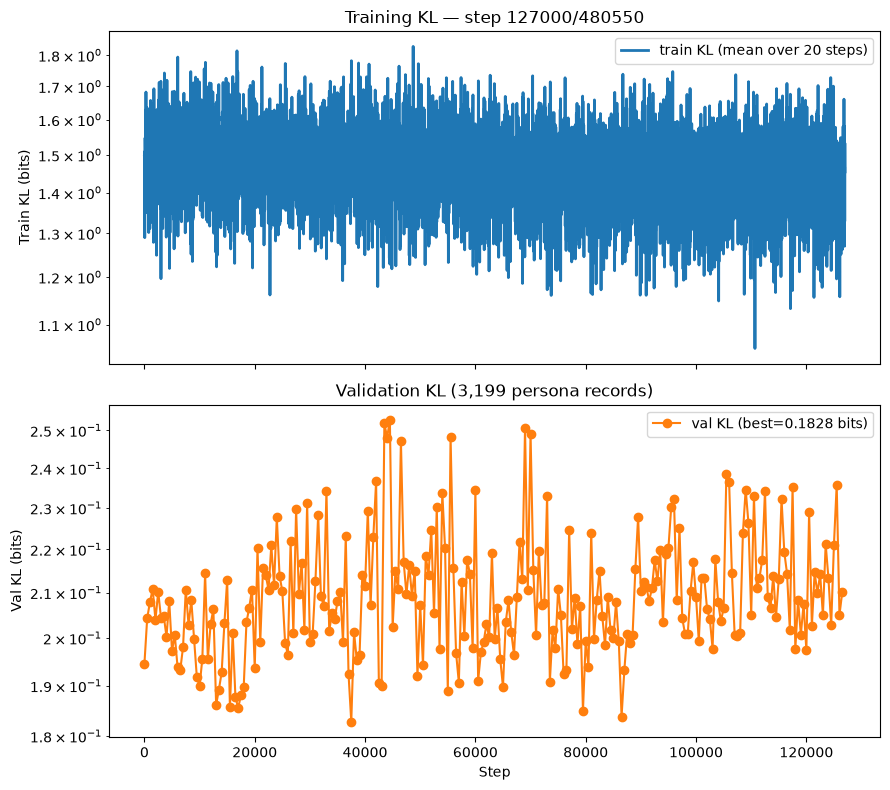

,epoch,step,train_kl,eval_kl,w1,delta_cns
0,0,0,—,0.1945,0.1088,-0.0207
1,1,500,1.4298,0.2042,0.1097,-0.0072
2,1,1000,1.4928,0.2079,0.1103,-0.0037
3,1,1500,1.5333,0.2108,0.1107,+0.0013
4,1,2000,1.5273,0.2039,0.1097,-0.0047
5,1,2500,1.4605,0.2102,0.1095,+0.0047
6,1,3000,1.1963,0.2044,0.1094,-0.0024
7,1,3500,1.6032,0.2048,0.1111,-0.0052
8,1,4000,1.5135,0.2003,0.1093,-0.0077
9,1,4500,1.5738,0.2081,0.1096,-0.0023


kev-0.8b-stage4-mix:   0%|          | 0/480550 [00:00<?, ?step/s]

KeyboardInterrupt: 

In [39]:
plotter_s4 = train_stage(
    model,
    train_records=train_combined,
    eval_records=eval_records,
    save_dir=stage4_dir,
    init_from=ckpt,
    epochs=5,
    lr=1e-5,
    batch_size=8,
    val_every=500,
    samples_per_epoch=None,
    resume=resume,
)

## Compare training

In [ ]:
model = None
rows = {"Initial (Zero-shot)": test_summary_init}
grummon2025_rows = {"Initial (Zero-shot)": grummon2025_summary_init}
for label, ckpt_dir in [
    ("Stage 1 (k=1, 10 ep)", stage1_dir / "best"),
    ("Stage 2 (k=2, 20 ep)", stage2_dir / "best"),
    ("Stage 3 (full, 5 ep)", stage3_dir / "best"),
    ("Stage 3 (mixed, 5 ep)", stage4_dir / "best"),
]:
    if (ckpt_dir / "head.pt").exists():
        m = load_checkpoint(ckpt_dir, device=device, trainable=False)
        summary, test_results_df = evaluate_model(m, issp_test_grouped, batch_size=64)
        grummon2025_summary, _ = evaluate_model(m, grummon2025_grouped, batch_size=128)
        rows[label] = summary
        grummon2025_rows[label] = grummon2025_summary
        del m
        free_gpu()

print("=== ISSP Test Set ===")
display(pd.DataFrame(rows).T.round(4))
print("\n=== Grummon 2025 RCT Test Set ===")
display(pd.DataFrame(grummon2025_rows).T.round(4))


In [ ]:
# By-attribute breakdown on the test set
display(test_results_df.groupby("attribute")[["ce", "dist_kl"]].mean())